In [3]:

import pandas as pd

# Carregar os dados preparados pelo colega
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")

X_train_scaled = pd.read_csv("X_train_scaled.csv")
X_test_scaled = pd.read_csv("X_test_scaled.csv")

y_train = pd.read_csv("y_train.csv").iloc[:, 0]
y_test = pd.read_csv("y_test.csv").iloc[:, 0]

# Conferir as dimensões
print("Treino:", X_train.shape)
print("Teste:", X_test.shape)
print("Treino padronizado:", X_train_scaled.shape)
print("Teste padronizado:", X_test_scaled.shape)

print("\nClasses no treino:")
print(y_train.value_counts())

print("\nClasses no teste:")
print(y_test.value_counts())


Treino: (814, 11)
Teste: (204, 11)
Treino padronizado: (814, 11)
Teste padronizado: (204, 11)

Classes no treino:
quality_class
0    704
1    110
Name: count, dtype: int64

Classes no teste:
quality_class
0    177
1     27
Name: count, dtype: int64


In [4]:
import os

# Mostrar a pasta de trabalho e os arquivos disponíveis
print("Pasta atual:", os.getcwd())
print("Arquivos encontrados:", os.listdir("."))


Pasta atual: /content
Arquivos encontrados: ['.config', 'X_train.csv', 'X_test_scaled.csv', 'y_test.csv', 'y_train.csv', 'X_train_scaled.csv', 'X_test.csv', 'sample_data']


In [5]:
from sklearn.linear_model import LogisticRegression

# Criar o modelo
modelo_logistico = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

# Treinar com os dados padronizados
modelo_logistico.fit(X_train_scaled, y_train)

# Fazer previsões nos dados de teste
previsoes_logistica = modelo_logistico.predict(X_test_scaled)

print("Regressão Logística treinada com sucesso!")
print("Quantidade de previsões:", len(previsoes_logistica))
print("Primeiras 10 previsões:", previsoes_logistica[:10])

Regressão Logística treinada com sucesso!
Quantidade de previsões: 204
Primeiras 10 previsões: [1 1 0 0 0 0 0 0 0 0]


In [6]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Calcular as métricas
acuracia = accuracy_score(y_test, previsoes_logistica)
precisao = precision_score(y_test, previsoes_logistica)
recall = recall_score(y_test, previsoes_logistica)
f1 = f1_score(y_test, previsoes_logistica)

print("RESULTADOS — REGRESSÃO LOGÍSTICA")
print(f"Acurácia: {acuracia:.2%}")
print(f"Precisão: {precisao:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-score: {f1:.2%}")

print("\nRELATÓRIO COMPLETO")
print(classification_report(y_test, previsoes_logistica))


RESULTADOS — REGRESSÃO LOGÍSTICA
Acurácia: 78.43%
Precisão: 35.59%
Recall: 77.78%
F1-score: 48.84%

RELATÓRIO COMPLETO
              precision    recall  f1-score   support

           0       0.96      0.79      0.86       177
           1       0.36      0.78      0.49        27

    accuracy                           0.78       204
   macro avg       0.66      0.78      0.68       204
weighted avg       0.88      0.78      0.81       204



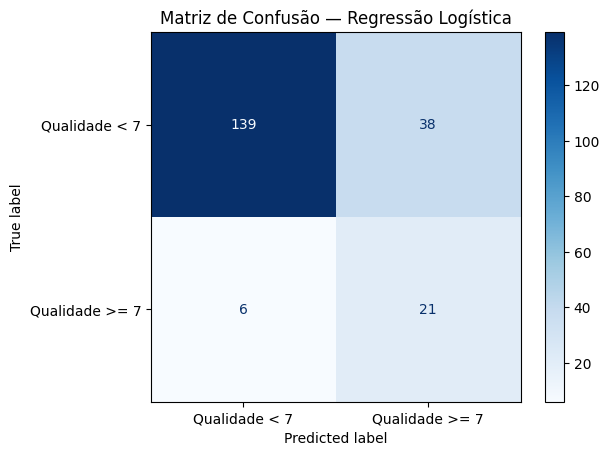

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calcular a matriz de confusão
matriz_logistica = confusion_matrix(
    y_test,
    previsoes_logistica
)

# Exibir o gráfico
disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_logistica,
    display_labels=["Qualidade < 7", "Qualidade >= 7"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão — Regressão Logística")
plt.show()

In [8]:

from sklearn.ensemble import RandomForestClassifier

# Criar o modelo
modelo_rf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Treinar o modelo
modelo_rf.fit(X_train, y_train)

# Fazer previsões
previsoes_rf = modelo_rf.predict(X_test)

print("Random Forest treinado com sucesso!")
print("Quantidade de previsões:", len(previsoes_rf))
print("Primeiras 10 previsões:", previsoes_rf[:10])

Random Forest treinado com sucesso!
Quantidade de previsões: 204
Primeiras 10 previsões: [0 0 0 0 0 0 0 0 0 0]


In [9]:
# Calcular as métricas do Random Forest
acuracia_rf = accuracy_score(y_test, previsoes_rf)
precisao_rf = precision_score(y_test, previsoes_rf, zero_division=0)
recall_rf = recall_score(y_test, previsoes_rf, zero_division=0)
f1_rf = f1_score(y_test, previsoes_rf, zero_division=0)

print("RESULTADOS — RANDOM FOREST")
print(f"Acurácia: {acuracia_rf:.2%}")
print(f"Precisão: {precisao_rf:.2%}")
print(f"Recall: {recall_rf:.2%}")
print(f"F1-score: {f1_rf:.2%}")

print("\nRELATÓRIO COMPLETO")
print(classification_report(y_test, previsoes_rf))

RESULTADOS — RANDOM FOREST
Acurácia: 90.69%
Precisão: 90.00%
Recall: 33.33%
F1-score: 48.65%

RELATÓRIO COMPLETO
              precision    recall  f1-score   support

           0       0.91      0.99      0.95       177
           1       0.90      0.33      0.49        27

    accuracy                           0.91       204
   macro avg       0.90      0.66      0.72       204
weighted avg       0.91      0.91      0.89       204



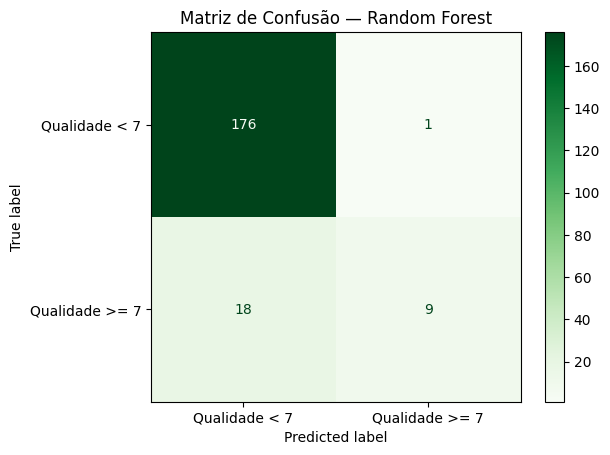

In [10]:
# Matriz de confusão — Random Forest
matriz_rf = confusion_matrix(y_test, previsoes_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_rf,
    display_labels=["Qualidade < 7", "Qualidade >= 7"]
)

disp.plot(cmap="Greens", values_format="d")
plt.title("Matriz de Confusão — Random Forest")
plt.show()


In [11]:
from sklearn.metrics import roc_auc_score

# Probabilidades da classe 1
prob_logistica = modelo_logistico.predict_proba(
    X_test_scaled
)[:, 1]

prob_rf = modelo_rf.predict_proba(
    X_test
)[:, 1]

# Calcular AUC-ROC
auc_logistica = roc_auc_score(y_test, prob_logistica)
auc_rf = roc_auc_score(y_test, prob_rf)

print("AUC-ROC — Regressão Logística:",
      f"{auc_logistica:.4f}")

print("AUC-ROC — Random Forest:",
      f"{auc_rf:.4f}")


AUC-ROC — Regressão Logística: 0.8818
AUC-ROC — Random Forest: 0.9317


### Análise exploratória de limiares no conjunto de teste (não utilizada na seleção)

**Atenção metodológica:** esta tabela serve exclusivamente para observar, de forma exploratória, como diferentes limiares se comportam no conjunto de teste. Ela **não deve ser usada para escolher, ajustar ou justificar o limiar final**. A seleção oficial foi feita anteriormente, usando probabilidades *out-of-fold* da validação cruzada estratificada aplicada somente ao conjunto de treinamento. O limiar de 0,25 foi então congelado e avaliado uma única vez no teste reservado.

In [12]:
# Comparação exploratória no teste — não selecionar o limiar com estes resultados
# Esta tabela é apenas descritiva; a seleção oficial ocorre na validação cruzada do treino.
import pandas as pd

resultados_limites = []

for limite in [0.20, 0.30, 0.40, 0.50]:
    previsoes = (prob_rf >= limite).astype(int)

    resultados_limites.append({
        "Limiar": limite,
        "Precisão": precision_score(
            y_test, previsoes, zero_division=0
        ),
        "Recall": recall_score(
            y_test, previsoes, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, previsoes, zero_division=0
        )
    })

tabela_limites = pd.DataFrame(resultados_limites)
display(tabela_limites.round(4))


,Limiar,Precisão,Recall,F1-score
0,0.2,0.5000,0.8889,0.6400
1,0.3,0.6207,0.6667,0.6429
2,0.4,0.7500,0.4444,0.5581
3,0.5,0.9091,0.3704,0.5263


In [13]:
import numpy as np

previsoes_05 = (prob_rf >= 0.50).astype(int)

print("Previsões diferentes:",
      np.sum(previsoes_rf != previsoes_05))

print("Probabilidades exatamente iguais a 0.50:",
      np.sum(np.isclose(prob_rf, 0.50, atol=1e-12, rtol=0)))

print("Matriz usando predict():")
print(confusion_matrix(y_test, previsoes_rf))

print("\nMatriz usando probabilidade >= 0.50:")
print(confusion_matrix(y_test, previsoes_05))


Previsões diferentes: 1
Probabilidades exatamente iguais a 0.50: 1
Matriz usando predict():
[[176   1]
 [ 18   9]]

Matriz usando probabilidade >= 0.50:
[[176   1]
 [ 17  10]]


In [14]:

from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Criar 5 divisões preservando a proporção das classes
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Obter probabilidades por validação cruzada
prob_rf_validacao = cross_val_predict(
    modelo_rf,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Validação cruzada concluída!")
print("Quantidade de probabilidades:",
      len(prob_rf_validacao))


Validação cruzada concluída!
Quantidade de probabilidades: 814


In [15]:

import numpy as np

resultados_validacao = []

# Testar limiares de 0.10 até 0.90
for limite in np.arange(0.10, 0.91, 0.05):
    previsoes = (
        prob_rf_validacao >= limite
    ).astype(int)

    resultados_validacao.append({
        "Limiar": round(limite, 2),
        "Precisão": precision_score(
            y_train, previsoes, zero_division=0
        ),
        "Recall": recall_score(
            y_train, previsoes, zero_division=0
        ),
        "F1-score": f1_score(
            y_train, previsoes, zero_division=0
        )
    })

tabela_validacao = pd.DataFrame(
    resultados_validacao
)

# Ordenar pelo maior F1-score
tabela_validacao = tabela_validacao.sort_values(
    "F1-score", ascending=False
)

display(tabela_validacao.head(10).round(4))


,Limiar,Precisão,Recall,F1-score
3,0.25,0.4331,0.6182,0.5094
1,0.15,0.3728,0.7727,0.5030
2,0.20,0.4011,0.6636,0.5000
4,0.30,0.4552,0.5545,0.5000
0,0.10,0.3418,0.8545,0.4883
5,0.35,0.4906,0.4727,0.4815
6,0.40,0.5185,0.3818,0.4398
7,0.45,0.6066,0.3364,0.4327
8,0.50,0.6000,0.2727,0.3750
9,0.55,0.7429,0.2364,0.3586


In [16]:

# Limiar escolhido na validação cruzada
limiar_final = 0.25

# Aplicar o limiar às probabilidades do teste
previsoes_rf_ajustado = (
    prob_rf >= limiar_final
).astype(int)

# Calcular métricas finais
print("RANDOM FOREST — LIMIAR AJUSTADO")
print("Limiar:", limiar_final)

print(
    "Acurácia:",
    f"{accuracy_score(y_test, previsoes_rf_ajustado):.2%}"
)
print(
    "Precisão:",
    f"{precision_score(y_test, previsoes_rf_ajustado):.2%}"
)
print(
    "Recall:",
    f"{recall_score(y_test, previsoes_rf_ajustado):.2%}"
)
print(
    "F1-score:",
    f"{f1_score(y_test, previsoes_rf_ajustado):.2%}"
)

print("\nMATRIZ DE CONFUSÃO")
print(confusion_matrix(y_test, previsoes_rf_ajustado))


RANDOM FOREST — LIMIAR AJUSTADO
Limiar: 0.25
Acurácia: 88.24%
Precisão: 54.05%
Recall: 74.07%
F1-score: 62.50%

MATRIZ DE CONFUSÃO
[[160  17]
 [  7  20]]


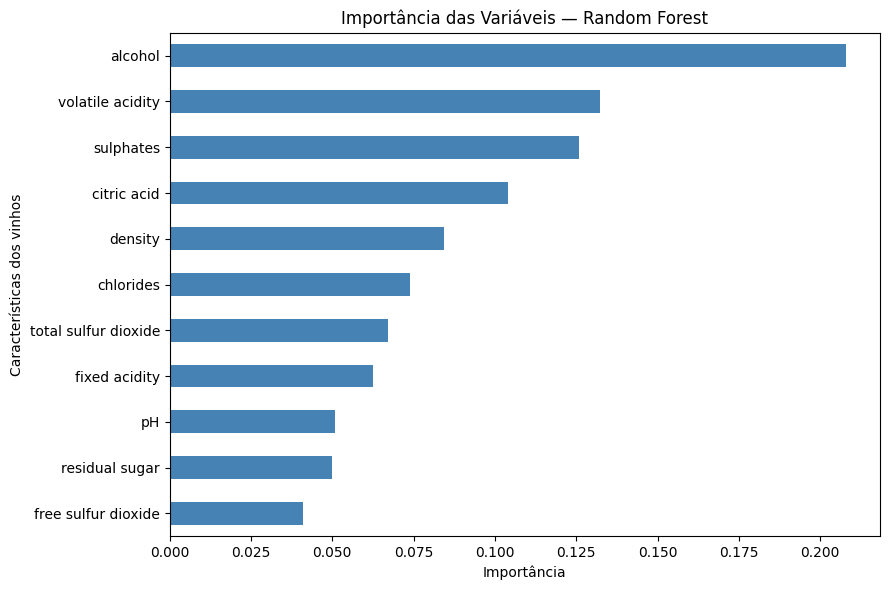

alcohol                 0.207997
volatile acidity        0.132220
sulphates               0.125784
citric acid             0.104061
density                 0.084386
chlorides               0.074034
total sulfur dioxide    0.067255
fixed acidity           0.062554
pH                      0.050737
residual sugar          0.049997
free sulfur dioxide     0.040975
dtype: float64


In [17]:

import pandas as pd
import matplotlib.pyplot as plt

# Importância das variáveis no Random Forest
importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=True)

# Criar gráfico
plt.figure(figsize=(9, 6))

importancias.plot(
    kind="barh",
    color="steelblue"
)

plt.title("Importância das Variáveis — Random Forest")
plt.xlabel("Importância")
plt.ylabel("Características dos vinhos")
plt.tight_layout()
plt.show()

# Mostrar os valores
print(importancias.sort_values(ascending=False))


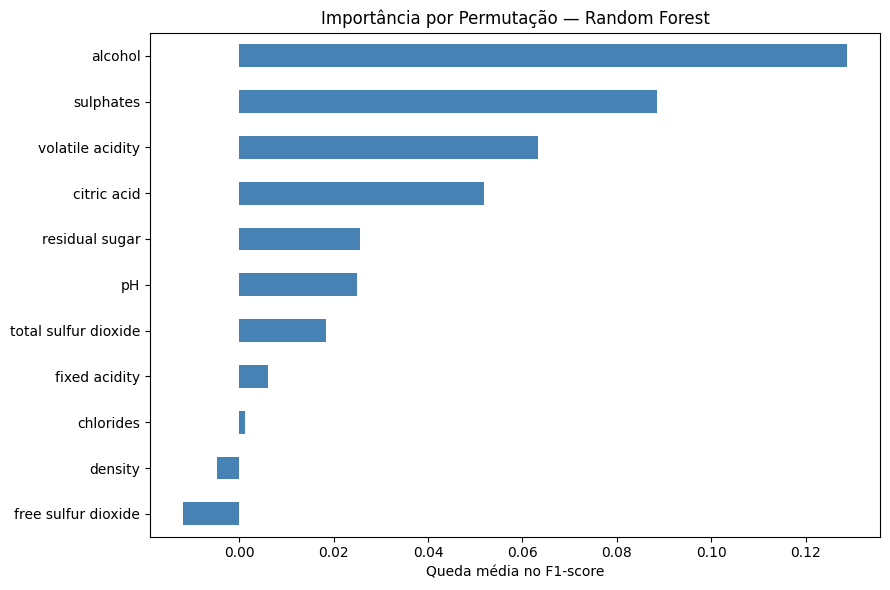

In [18]:

from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score

# Avaliar importância usando o modelo com limiar ajustado
classificador_ajustado = lambda X: (
    modelo_rf.predict_proba(X)[:, 1] >= 0.25
).astype(int)

# Função para calcular F1 com o limiar escolhido
def f1_ajustado(modelo, X, y):
    previsoes = (
        modelo.predict_proba(X)[:, 1] >= 0.25
    ).astype(int)
    return f1_score(y, previsoes, zero_division=0)

resultado_permutacao = permutation_importance(
    modelo_rf,
    X_test,
    y_test,
    scoring=f1_ajustado,
    n_repeats=20,
    random_state=42,
    n_jobs=-1
)

importancia_permutacao = pd.Series(
    resultado_permutacao.importances_mean,
    index=X_test.columns
).sort_values()

importancia_permutacao.plot(
    kind="barh",
    figsize=(9, 6),
    color="steelblue"
)

plt.title("Importância por Permutação — Random Forest")
plt.xlabel("Queda média no F1-score")
plt.tight_layout()
plt.show()
